**IMPORT**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 60)

**LOAD DATA**

In [ ]:
df = pd.read_csv("../data/diabetic_data.csv")
print(df.shape)
df.head()

(101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      101766 non-null  str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    101766 non-null  str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                101766 non-null  str  
 11  medical_specialty         101766 non-null  str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

In [4]:
df.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


**HANDLE MISSING VALUES**

In [ ]:
df = df.replace("?", np.nan)
missing = df.isnull().mean().sort_values(ascending=False) * 100
missing[missing > 0].round(1)

weight               96.9
max_glu_serum        94.7
A1Cresult            83.3
medical_specialty    49.1
payer_code           39.6
race                  2.2
diag_3                1.4
diag_2                0.4
diag_1                0.0
dtype: float64

**CREATE THE TARGET**

In [ ]:
print(df["readmitted"].value_counts())

df["target"] = (df["readmitted"] == "<30").astype(int)
print(df["target"].value_counts(normalize=True).round(3))

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64
target
0    0.888
1    0.112
Name: proportion, dtype: float64


**CHART REPRESENTATION**

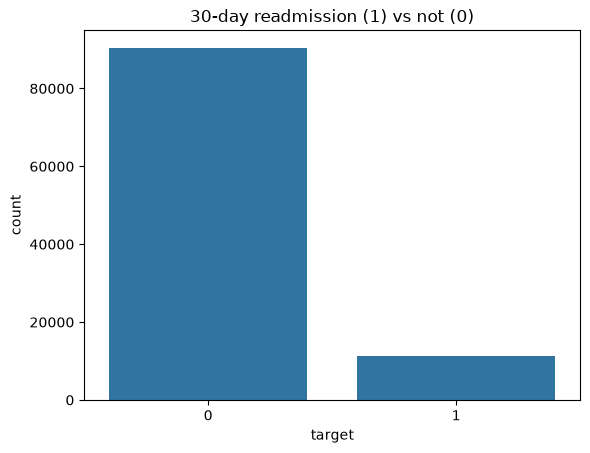

In [8]:
#Chart Representation
sns.countplot(x="target", data=df)
plt.title("30-day readmission (1) vs not (0)")
plt.savefig("../reports/figures", dpi=150, bbox_inches="tight")
plt.show()

**CLEANING THE DATA**

In [9]:

#Remove patients who can't be readmitted (died or went to hospice):
before = len(df)
df = df[~df["discharge_disposition_id"].isin([11, 13, 14, 19, 20, 21])]
print("Removed:", before - len(df), "| Remaining:", len(df))

Removed: 2423 | Remaining: 99343


In [10]:
#Keep one encounter per patient (prevents leakage between train and test):
print("Unique patients:", df["patient_nbr"].nunique(), "of", len(df), "rows")
df = df.drop_duplicates(subset="patient_nbr", keep="first")
print("Rows now:", len(df))

Unique patients: 69990 of 99343 rows
Rows now: 69990


In [11]:
#Drop useless columns:
df = df.drop(columns=["weight", "payer_code", "encounter_id", "patient_nbr"])

In [12]:
#Fill remaining missing values:
df["race"] = df["race"].fillna("Unknown")
df["medical_specialty"] = df["medical_specialty"].fillna("Unknown")
for col in ["diag_1", "diag_2", "diag_3"]:
    df[col] = df[col].fillna("Unknown")

df = df[df["gender"] != "Unknown/Invalid"]
df.isnull().sum().sum()

np.int64(123779)

**FIRST INSIGHT**

In [13]:
print(df.groupby("age")["target"].mean().round(3))
print(df.groupby(pd.cut(df["number_inpatient"], [-1, 0, 1, 2, 100]))["target"].mean().round(3))

age
[0-10)      0.020
[10-20)     0.049
[20-30)     0.074
[30-40)     0.070
[40-50)     0.074
[50-60)     0.071
[60-70)     0.090
[70-80)     0.102
[80-90)     0.108
[90-100)    0.095
Name: target, dtype: float64
number_inpatient
(-1, 0]     0.081
(0, 1]      0.129
(1, 2]      0.185
(2, 100]    0.265
Name: target, dtype: float64


**SAVE CLEANED DATA**

In [14]:
df.to_csv("../data/cleaned_data.csv", index=False)
print(df.shape)

(69987, 47)
